# Reading iC IR and iC FBRM files with PharmaPy

`PharmaPy.PATReaders` reads the native files of Mettler Toledo iC IR, iC Raman and iC FBRM directly. No vendor software and no manual export are needed.

This notebook reads one azithromycin run (high seed load, fast cooling) and looks at what comes back.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

from PharmaPy import PATReaders

# Folder of one run. It holds one .iCIR, one .iCRaman and one .icFbrm file.
RUN_FOLDER = Path(r"<folder of one run>")

ir_file, = RUN_FOLDER.glob("*.iCIR")
raman_file, = RUN_FOLDER.glob("*.iCRaman")
fbrm_file, = RUN_FOLDER.glob("*.icFbrm")

# Plot style: one blue ramp for curves ordered in time, three colours for the count bands.
RAMP = ["#86b6ef", "#5598e7", "#2a78d6", "#1c5cab", "#0d366b"]
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": "#e6e5e1", "grid.linewidth": 0.6, "figure.dpi": 110})

## IR spectra

One call returns the sample times, the wavenumber axis and the absorbance of every spectrum.

In [2]:
ir = PATReaders.read_ic_spectra(ir_file)

print("written by       ", ir.software, ir.build)
print("time             ", ir.time.shape, ir.time.dtype, "UTC")
print("wavenumber       ", ir.wavenumber.shape, "from", ir.wavenumber[0], "to", ir.wavenumber[-1], "cm-1")
print("absorbance       ", ir.absorbance.shape, "(spectra, points)")
print("first spectrum   ", ir.time[0])
print("last spectrum    ", ir.time[-1])
print("spectra left out ", len(ir.without_time), "(stored without a sample time)")

written by        iC IR 7.1.91.0
time              (864,) datetime64[us] UTC
wavenumber        (589,) from 3000.0 to 648.0 cm-1
absorbance        (864, 589) (spectra, points)
first spectrum    2026-10-20T18:02:29.085004
last spectrum     2026-10-21T09:01:25.655228
spectra left out  0 (stored without a sample time)


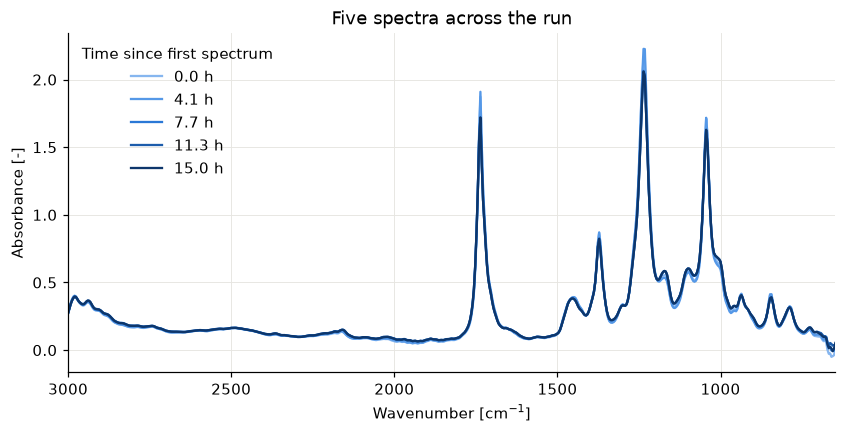

In [3]:
ir_hours = (ir.time - ir.time[0]) / np.timedelta64(1, "h")  # [h] since the first spectrum
rows = np.linspace(0, ir_hours.size - 1, len(RAMP)).astype(int)

fig, ax = plt.subplots(figsize=(9, 4))
for row, colour in zip(rows, RAMP):
    ax.plot(ir.wavenumber, ir.absorbance[row], color=colour, lw=1.5, label="%.1f h" % ir_hours[row])
ax.set_xlim(ir.wavenumber.max(), ir.wavenumber.min())  # high wavenumber on the left, as IR spectra are drawn
ax.set(xlabel="Wavenumber [cm$^{-1}$]", ylabel="Absorbance [-]", title="Five spectra across the run")
ax.legend(title="Time since first spectrum", frameon=False);

The spectra look alike because ethyl acetate dominates them. The change during the run is small, so it shows better as a trend at one wavenumber.

The point at 1000 cm$^{-1}$ is only an illustration. In this system no single point follows the dissolved solute alone, so this trend is not a concentration.

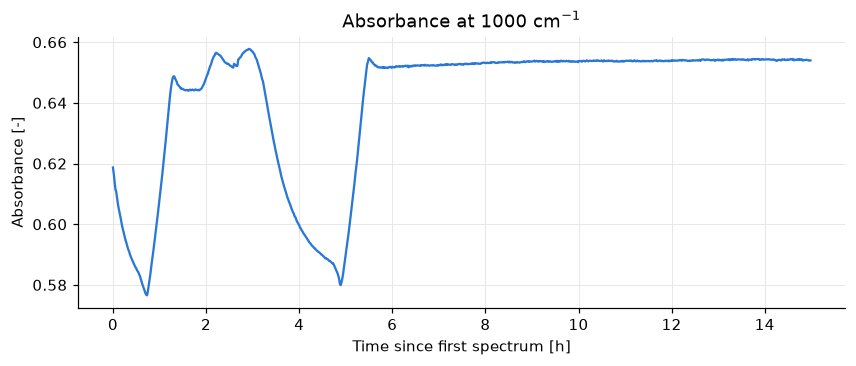

In [4]:
PROBE_WAVENUMBER = 1000.0  # [cm-1] any point of interest
column = int(np.argmin(np.abs(ir.wavenumber - PROBE_WAVENUMBER)))

fig, ax = plt.subplots(figsize=(9, 3.2))
ax.plot(ir_hours, ir.absorbance[:, column], color=BLUE, lw=1.5)
ax.set(xlabel="Time since first spectrum [h]", ylabel="Absorbance [-]",
       title="Absorbance at %.0f cm$^{-1}$" % ir.wavenumber[column]);

## FBRM chord lengths

The second call returns the sample times, the edges of the chord-length channels and the counts in each channel.

In [5]:
fbrm = PATReaders.read_ic_fbrm(fbrm_file)

print("written by    ", fbrm.software, fbrm.build)
print("time          ", fbrm.time.shape, fbrm.time.dtype, "local time of the lab computer")
print("channel_edges ", fbrm.channel_edges.shape, "from", fbrm.channel_edges[0], "to", fbrm.channel_edges[-1], "um")
print("counts        ", fbrm.counts.shape, "(samples, channels)")
print("first sample  ", fbrm.time[0])
print("last sample   ", fbrm.time[-1])

written by     iC FBRM 4.4.33.0
time           (5393,) datetime64[us] local time of the lab computer
channel_edges  (1551,) from 0.0 to 1800.0 um
counts         (5393, 1550) (samples, channels)
first sample   2026-10-20T13:53:41.652068
last sample    2026-10-21T04:53:27.879273


The raw channels are narrow (0.2 um) at small chords and wide (2 um) at large ones. `rebin_matrix` moves the counts to any other grid. Here: 100 logarithmic channels from 1 to 1000 um, the grid iC FBRM displays.

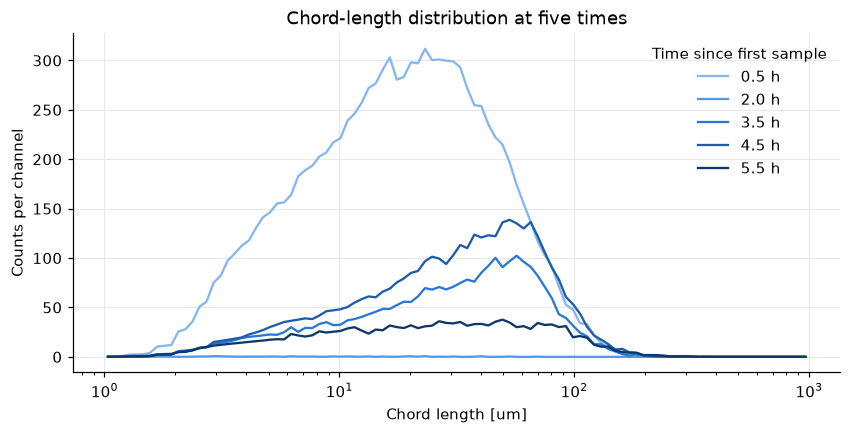

In [6]:
log_edges = np.logspace(0, 3, 101)  # [um] 100 channels from 1 to 1000 um
midpoints = np.sqrt(log_edges[:-1] * log_edges[1:])  # [um]
distributions = fbrm.counts @ PATReaders.rebin_matrix(fbrm.channel_edges, log_edges)  # [counts per channel]

fbrm_hours = (fbrm.time - fbrm.time[0]) / np.timedelta64(1, "h")  # [h] since the first sample
sample_hours = [0.5, 2.0, 3.5, 4.5, 5.5]  # [h] times to show

fig, ax = plt.subplots(figsize=(9, 4))
for hour, colour in zip(sample_hours, RAMP):
    row = int(np.argmin(np.abs(fbrm_hours - hour)))
    ax.semilogx(midpoints, distributions[row], color=colour, lw=1.5, label="%.1f h" % fbrm_hours[row])
ax.set(xlabel="Chord length [um]", ylabel="Counts per channel", title="Chord-length distribution at five times")
ax.legend(title="Time since first sample", frameon=False);

The same matrix gives the counts in bands, for example the three bands iC FBRM reports. The run starts as a slurry, which dissolves on heating. The counts step up when the seed is added and grow during cooling.

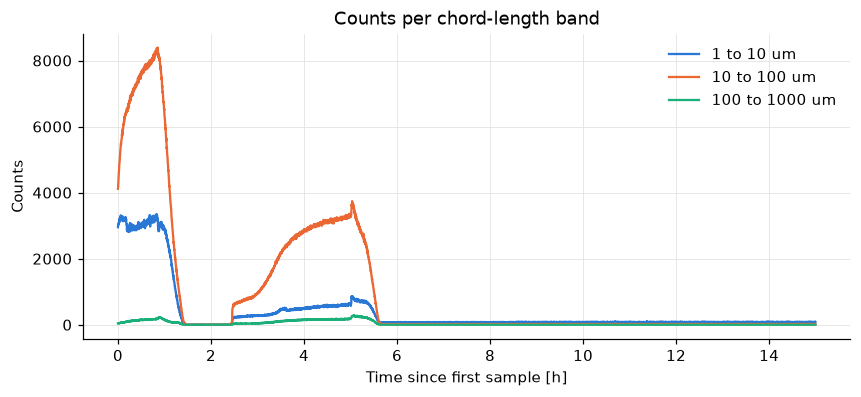

In [7]:
band_edges = np.array([1.0, 10.0, 100.0, 1000.0])  # [um]
bands = fbrm.counts @ PATReaders.rebin_matrix(fbrm.channel_edges, band_edges)  # [counts], shape (samples, 3)

fig, ax = plt.subplots(figsize=(9, 3.6))
for index, (name, colour) in enumerate(zip(["1 to 10 um", "10 to 100 um", "100 to 1000 um"], [BLUE, ORANGE, AQUA])):
    ax.plot(fbrm_hours, bands[:, index], color=colour, lw=1.5, label=name)
ax.set(xlabel="Time since first sample [h]", ylabel="Counts", title="Counts per chord-length band")
ax.legend(frameon=False);

## One clock for both instruments

The IR file stores UTC. The FBRM file stores the local time of the lab computer. Shift one of them by the UTC offset of that day and both are on the same clock.

Both instruments kept recording for nine hours after the thermostat log of this run ends, so the plot stops at 6.5 h.

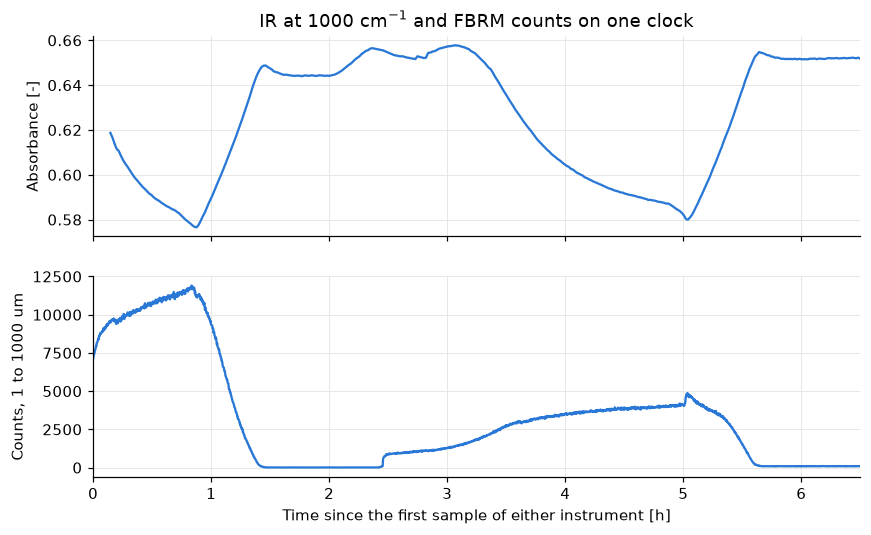

In [8]:
UTC_OFFSET_H = -4  # [h] local time minus UTC on the day of the run (US Eastern daylight time)
ir_local = ir.time + np.timedelta64(UTC_OFFSET_H, "h")
start = min(ir_local[0], fbrm.time[0])
ir_clock = (ir_local - start) / np.timedelta64(1, "h")  # [h]
fbrm_clock = (fbrm.time - start) / np.timedelta64(1, "h")  # [h]

fig, (top, bottom) = plt.subplots(2, 1, figsize=(9, 5.2), sharex=True)
top.plot(ir_clock, ir.absorbance[:, column], color=BLUE, lw=1.5)
top.set(ylabel="Absorbance [-]", title="IR at %.0f cm$^{-1}$ and FBRM counts on one clock" % ir.wavenumber[column])
bottom.plot(fbrm_clock, bands.sum(axis=1), color=BLUE, lw=1.5)
bottom.set(xlabel="Time since the first sample of either instrument [h]", ylabel="Counts, 1 to 1000 um", xlim=(0, 6.5));

## Raman files

The same call reads an iC Raman file. Its ordinate is an intensity, so it is read from `values`. Asking for `absorbance` raises an error instead of handing over the wrong quantity.

In [9]:
raman = PATReaders.read_ic_spectra(raman_file)

print("written by ", raman.software, raman.build)
print("ordinate   ", raman.value_units)
print("values     ", raman.values.shape, "(spectra, points)")
print("shift      ", raman.wavenumber[0], "to", raman.wavenumber[-1], "cm-1")
try:
    raman.absorbance
except ValueError as error:
    print("absorbance ", error)

written by  iC Raman 8.0.114.0
ordinate    Intensity
values      (876, 3251) (spectra, points)
shift       3400.0 to 150.0 cm-1
absorbance  These spectra hold 'Intensity', not absorbance; read them from 'values'.


## What the readers tell you

- **Software build.** The formats are not documented by the vendor. They were checked against vendor exports for iC IR 7.1.91.0, iC Raman 8.0.114.0 and iC FBRM 4.4.33.0. A file from another build is still read, with a warning to compare one export first.
- **Spectra without a time.** A spectrum stored without a metadata entry is left out. Its identifier is listed in `without_time`.
- **Files without samples.** An FBRM file that recorded nothing raises a `ValueError`. The slow-cool, high-seed run of this campaign is such a file.
- **Channel grid.** The FBRM channel edges were inferred by matching one run to its export. They are not a vendor specification.